# MM6 lab: many users, one channel (30 min)

**What changed since MM5.** Your link now has neighbours. Several users (Zoya, Yoshi, Xia, ...) send to the base station Basil over one shared, slotted channel. If two transmit in the same slot, both frames are lost.

```
each user:  application → stop-and-wait ARQ (MM5) → MAC (today) ─┐
                                                                 ├─ shared channel ─► Basil
                                   other users ... ──────────────┘
```

The link layer is the reference stop-and-wait from MM5. To run your own instead, add `link=(StopAndWaitSender, StopAndWaitReceiver)` from `student.mm5_link`.

**What you build:** MAC protocols in `student/mm6_mac.py`, with Copilot. A MAC answers one question at the start of each slot: *transmit now, yes or no?*

| Part | Time | |
|---|---|---|
| A | 5 min | Why MM5's protocol breaks on a shared channel |
| B | 8 min | Implement slotted ALOHA with Copilot |
| C | 15 min | Pick **two** experiments |
| D | 2 min | Wrap up (optional challenge for home) |

**Rules.** Prediction first, then run. Copilot writes code in `student/` only.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.insert(0, "..")   # the CommSim folder
import matplotlib.pyplot as plt
from commsim import *
from commsim.checks import check_mm6_aloha
from student.mm6_mac import AlwaysTransmit, RoundRobinTDMA, SlottedAloha, GroupedAloha, BackoffAloha, MyMAC

## Part A: why MM5's protocol breaks (5 min)

`AlwaysTransmit` is what the MM5 link does on its own: send whenever there is a frame. Three users, each always has data.

**A1. Predict first:** what throughput (successful slots per slot) will you get?

> **Answer:** Zero. All three transmit in slot 0 and collide, and they do the same in every slot after that.

shared_uplink: 3 users, AlwaysTransmit, 200 slots
  time simulated       0.03998 s
  data frames sent     603  (of which retransmissions: 600)
  ACK frames sent      0
  failed error check   0  (frames)
  delivered correctly  0 of 3 offered
  duplicates           0
  undetected errors    0
  never delivered      3
  goodput              0 bit/s  (0.0 % of the link rate)
  mean delay           nan s
  slots                200: 0 success, 200 collision, 0 idle, 0 bit-error
  throughput           0.000 packets/slot
  fairness (Jain)      nan
  per user             Zoya: 0, Yoshi: 0, Xia: 0


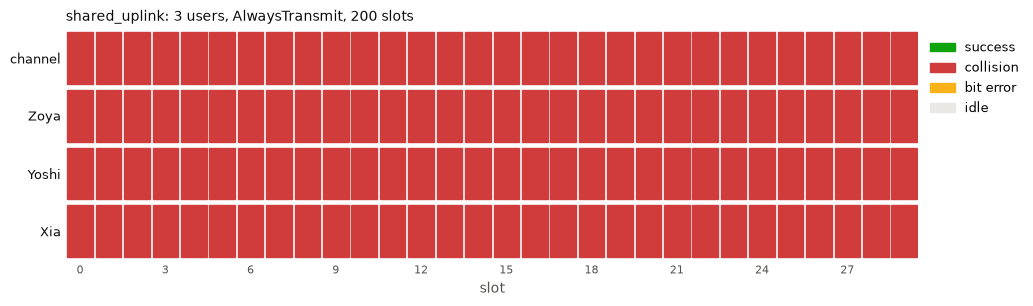

In [2]:
r = shared_uplink(AlwaysTransmit, n_users=3, n_slots=200)
print(r)
slot_grid(r, n_slots=30);

**A2.** Why does stop-and-wait ARQ never recover here? What would the users have to do differently?

> **Answer:** After a collision nobody gets an ACK, so every user retransmits in the next slot, exactly in step with the others, and they collide again. ARQ fixes losses caused by noise, but here the loss is caused by the users themselves. They need to break the symmetry: either by randomness (wait a random time) or by coordination (agree on who sends when).

shared_uplink: 3 users, RoundRobinTDMA, 200 slots
  time simulated       0.03998 s
  data frames sent     203  (of which retransmissions: 0)
  ACK frames sent      200
  failed error check   0  (frames)
  delivered correctly  200 of 203 offered
  duplicates           0
  undetected errors    0
  never delivered      3
  goodput              6.403e+05 bit/s  (64.0 % of the link rate)
  mean delay           0.0005647 s
  slots                200: 200 success, 0 collision, 0 idle, 0 bit-error
  throughput           1.000 packets/slot
  fairness (Jain)      1.000
  per user             Zoya: 67, Yoshi: 67, Xia: 66


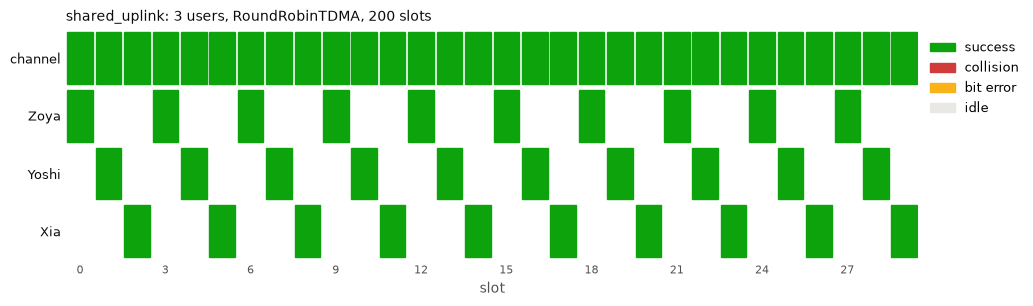

In [3]:
r = shared_uplink(RoundRobinTDMA, n_users=3, n_slots=200)
print(r)
slot_grid(r, n_slots=30);

**A3.** TDMA (given) fixes it. What does every user need to know for TDMA to work, that it would not need for random access?

> **Answer:** Its own slot number and how many users there are (here: index and N), plus a common slot clock. Someone (Basil) has to hand that out and update it when users join or leave. Slotted ALOHA needs only the slot clock.

## Part B: implement slotted ALOHA (8 min)

1. Open `student/mm6_mac.py` and read `AlwaysTransmit`, `RoundRobinTDMA` and the comments at the top.
2. Ask Copilot to implement `SlottedAloha.transmit_now`: in every slot in which the node has a frame, transmit with probability `p`.
3. Run the check: it compares your MAC with N·p·(1 − p)^(N−1) from Lecture 6.

In [4]:
check_mm6_aloha(SlottedAloha)

PASS  N= 2, p=0.5: simulated 0.490, theory 0.500


PASS  N= 5, p=0.2: simulated 0.412, theory 0.410


PASS  N=10, p=0.1: simulated 0.386, theory 0.387


PASS  N=10, p=0.3: simulated 0.121, theory 0.121

All checks passed.


True

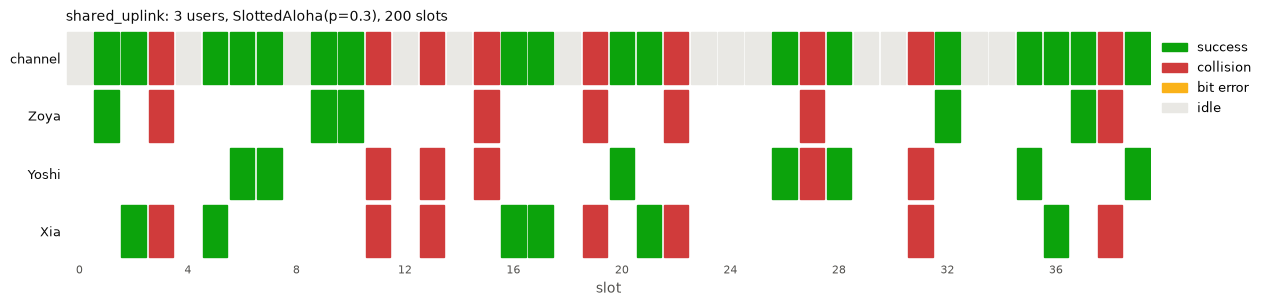

In [5]:
r = shared_uplink(SlottedAloha, mac_params={"p": 0.3}, n_users=3, n_slots=200)
slot_grid(r, n_slots=40);

**B1.** Find a collision in the grid. What happens to the two colliding users in the next slots, and why does it no longer go on forever?

> **Answer:** Both retransmit, but each only with probability p in each slot, independently. Sooner or later only one of them transmits and gets through. Randomness breaks the symmetry that deadlocked AlwaysTransmit.

## Part C: pick two experiments (15 min)

### C1. How eager should a user be?
Ten saturated users. Lecture 6 says the best p is 1/N.

**Predict:** what happens to throughput if every user is a bit too eager (p = 0.2) or too shy (p = 0.05)? Which mistake is worse?

> **Answer:** Typical prediction: both are equally bad, or being shy is worse.

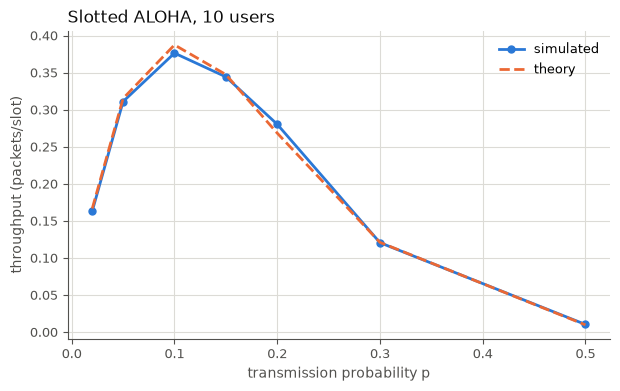

In [6]:
ps = [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
sim = [shared_uplink(SlottedAloha, mac_params={"p": p}, n_users=10, n_slots=3000).throughput for p in ps]
theory = [10 * p * (1 - p) ** 9 for p in ps]
sweep_plot(ps, {"simulated": sim, "theory": theory}, "transmission probability p",
           "throughput (packets/slot)", title="Slotted ALOHA, 10 users");

**C1.** Which mistake is worse? Now keep p = 0.1 and change the number of users. Ask Copilot to write the sweep (N from 2 to 30). What does this tell you about using slotted ALOHA when users don't know N?

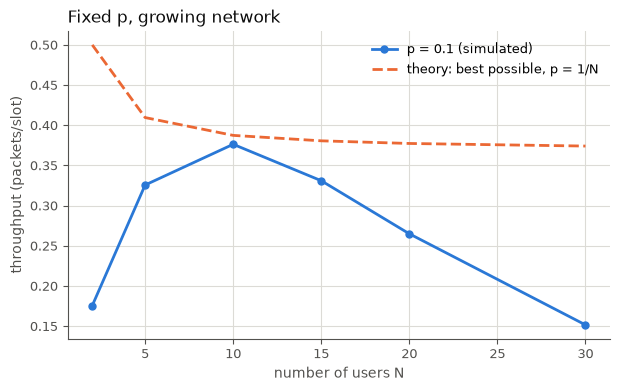

In [7]:
ns = [2, 5, 10, 15, 20, 30]
sim = [shared_uplink(SlottedAloha, mac_params={"p": 0.1}, n_users=n, n_slots=3000).throughput for n in ns]
best = [(1 - 1 / n) ** (n - 1) for n in ns]
sweep_plot(ns, {"p = 0.1 (simulated)": sim, "theory: best possible, p = 1/N": best},
           "number of users N", "throughput (packets/slot)", title="Fixed p, growing network");

> **Answer:** Too eager is worse: at p = 0.2 throughput falls to about 0.28, at p = 0.05 only to 0.31, and p = 0.5 almost kills the channel (0.01). Collisions waste a slot for everybody, idle slots only waste the slot. With p fixed at 0.1, throughput is close to optimal for N = 10 but collapses for N = 30 and wastes most slots for N = 2. A fixed p only works if users know N, which is exactly what random access was supposed to avoid.

### C2. Problem 2(c), and beyond
Twenty users: group A owns the even slots, group B the odd slots, and slotted ALOHA (p = 1/group size) runs inside each group.

1. Ask Copilot to implement `GroupedAloha` in `student/mm6_mac.py`.
2. Check your answer to Problem Set 2, Problem 2(c) with the 4 + 16 split.
3. Then try every split. **Predict first:** which split gives the highest total throughput?

> **Answer:** Typical prediction: an even split, 10 + 10.

In [8]:
shared_uplink(GroupedAloha, mac_params={"group_a": 4}, n_users=20, n_slots=20000).throughput

0.39835

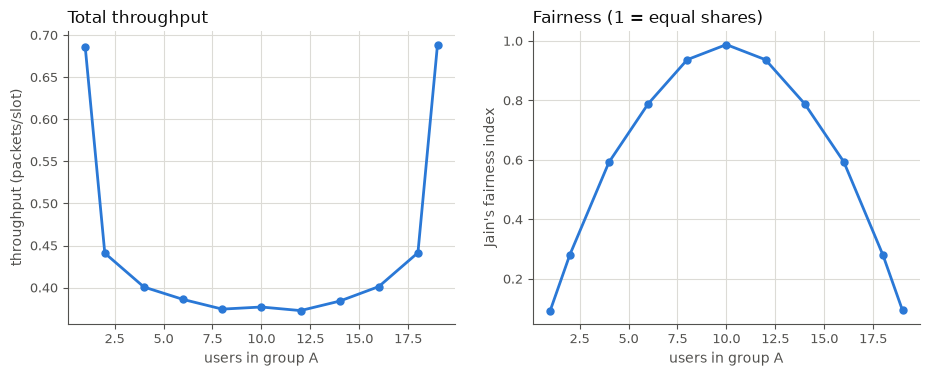

In [9]:
splits = [1, 2, 4, 6, 8, 10, 12, 14, 16, 18, 19]
runs = [shared_uplink(GroupedAloha, mac_params={"group_a": a}, n_users=20, n_slots=4000) for a in splits]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
sweep_plot(splits, {"throughput": [r.throughput for r in runs]}, "users in group A",
           "throughput (packets/slot)", title="Total throughput", ax=ax1)
sweep_plot(splits, {"fairness": [r.fairness for r in runs]}, "users in group A",
           "Jain's fairness index", title="Fairness (1 = equal shares)", ax=ax2);

**C2.** Did the simulation confirm your Problem 2(c) answer? Which split maximises throughput, which is fairest, and which would you deploy?

> **Answer:** Yes: about 0.40 packets/slot for 4 + 16, as in Problem 2(c). The total is highest for 1 + 19 (about 0.69), because the lone user in group A never collides, so half of all slots are perfect. But that user gets half the channel and the other 19 share the rest: fairness about 0.09. A 10 + 10 split is fairest (about 0.99) at about 0.38. We would deploy close to an even split. "Highest throughput" and "best system" are not the same thing.

### C3. What happens when the load grows?
Real users are not always busy. Each of 10 users gets new packets at random (Bernoulli arrivals). We raise the total load and compare three MACs.

1. Ask Copilot to implement `BackoffAloha` (binary exponential back-off; see its docstring).
2. **Predict:** which MAC is best at low load, and which at high load?

> **Answer:** Typical prediction: ALOHA at low load, TDMA at high load.

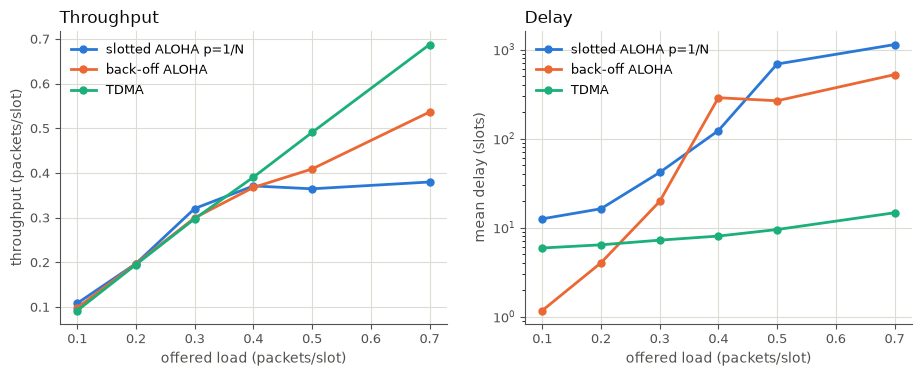

In [10]:
loads = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7]         # total packets per slot, all users together
macs = {"slotted ALOHA p=1/N": (SlottedAloha, {"p": 0.1}),
        "back-off ALOHA": (BackoffAloha, {}),
        "TDMA": (RoundRobinTDMA, {})}
thr, delay = {}, {}
for name, (mac, params) in macs.items():
    runs = [shared_uplink(mac, mac_params=params, n_users=10, traffic=load / 10, n_slots=5000) for load in loads]
    thr[name] = [r.throughput for r in runs]
    delay[name] = [r.mean_delay / r.net.slot_time for r in runs]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
sweep_plot(loads, thr, "offered load (packets/slot)", "throughput (packets/slot)", title="Throughput", ax=ax1)
sweep_plot(loads, delay, "offered load (packets/slot)", "mean delay (slots)", title="Delay", logy=True, ax=ax2);

**C3.** Where does each MAC break down? Back-off ALOHA may go above Lecture 6's 1/e limit at high load. Run the cell below: what does that cost?

In [11]:
r = shared_uplink(BackoffAloha, n_users=10, n_slots=5000)
print(r)

shared_uplink: 10 users, BackoffAloha, 5000 slots
  time simulated       1.04 s
  data frames sent     5136  (of which retransmissions: 361)
  ACK frames sent      4765
  failed error check   0  (frames)
  delivered correctly  4765 of 4775 offered
  duplicates           0
  undetected errors    0
  never delivered      10
  goodput              5.862e+05 bit/s  (58.6 % of the link rate)
  mean delay           0.0002435 s
  slots                5000: 4765 success, 164 collision, 71 idle, 0 bit-error
  throughput           0.953 packets/slot
  fairness (Jain)      0.126
  per user             Zoya: 3, Yoshi: 224, Xia: 4234, Walt: 297, Vera: 4, Ugo: 2, Tess: 1, Sam: 0, Rami: 0, Quinn: 0


> **Answer:** At low load the ALOHA variants beat TDMA on delay: a user with back-off sends at once (about 1 slot), while TDMA waits for its turn (about 6 slots) and slotted ALOHA with p = 0.1 hesitates (about 12 slots). Above about 0.37 packets/slot, slotted ALOHA saturates near 1/e and its delay explodes. TDMA carries everything up to 0.7 with a delay of about 15 slots. Back-off ALOHA gets above 1/e, but in the saturated run one user captures the channel: throughput 0.95, fairness 0.13. Whoever backs off least keeps winning.

## Part D: wrap up (2 min)

**D1.** One sentence: when would you choose random access over scheduling?

> **Answer:** When there are many users who send rarely and unpredictably (sensors, doorbells), so that reserved slots would mostly sit empty and the coordination overhead would cost more than the occasional collision.

### Optional challenge (at home): the connected neighbourhood
The pre-lecture reading's neighbourhood: 2 doorbells (rare bursts of 20 packets), 6 sensors (rare single packets), 1 video streamer (busy). Design `MyMAC` and beat the given MACs on **mean delay** without letting any user's delivery ratio drop below 90 %. Compare your result with other groups.

In [12]:
neighbourhood = lambda: [Bursty(0.002, 20), Bursty(0.002, 20)] + [Bernoulli(0.01) for _ in range(6)] + [Bernoulli(0.3)]
names = ["Door 1", "Door 2"] + [f"Sensor {i}" for i in range(1, 7)] + ["Stream"]
print(f"{'MAC':<22}{'throughput':>11}{'mean delay':>12}{'worst user':>12}")
for label, mac, params in [("TDMA", RoundRobinTDMA, {}), ("slotted ALOHA", SlottedAloha, {"p": 1 / 9}),
                           ("back-off ALOHA", BackoffAloha, {}), ("MyMAC", MyMAC, {})]:
    try:
        r = shared_uplink(mac, mac_params=params, n_users=9, traffic=neighbourhood(), user_names=names, n_slots=10000)
    except NotImplementedError:
        print(f"{label:<22}  not implemented yet"); continue
    worst = min(r.per_user[u] / max(1, r.per_user_offered[u]) for u in r.per_user)
    print(f"{label:<22}{r.throughput:>11.3f}{r.mean_delay / r.net.slot_time:>10.1f} sl{worst:>11.0%}")

MAC                    throughput  mean delay  worst user


TDMA                        0.240    1466.8 sl        37%


slotted ALOHA               0.226    1450.5 sl        31%


back-off ALOHA              0.442      23.9 sl        90%


MyMAC                       0.437      38.5 sl        92%
